In [1]:
import pandas as pd 
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('loan_approval_data.csv')
df = df.drop('Applicant_ID', axis=1)
df = df.dropna(subset ='Loan_Approved')

df.head()
df.shape
df.info()
df.isnull().sum()
print(df['Loan_Approved'].isnull().mean() * 100)

<class 'pandas.core.frame.DataFrame'>
Index: 950 entries, 0 to 999
Data columns (total 19 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Applicant_Income    902 non-null    float64
 1   Coapplicant_Income  902 non-null    float64
 2   Employment_Status   906 non-null    object 
 3   Age                 902 non-null    float64
 4   Marital_Status      902 non-null    object 
 5   Dependents          903 non-null    float64
 6   Credit_Score        902 non-null    float64
 7   Existing_Loans      901 non-null    float64
 8   DTI_Ratio           903 non-null    float64
 9   Savings             901 non-null    float64
 10  Collateral_Value    901 non-null    float64
 11  Loan_Amount         903 non-null    float64
 12  Loan_Term           902 non-null    float64
 13  Loan_Purpose        902 non-null    object 
 14  Property_Area       901 non-null    object 
 15  Education_Level     903 non-null    object 
 16  Gender       

## EDA

Text(0.5, 1.0, 'is loan approved or not')

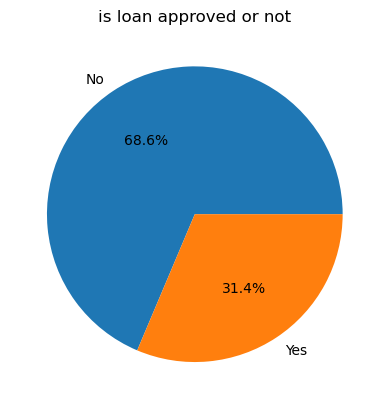

In [3]:
# How balance our classes

classes_count = df['Loan_Approved'].value_counts()

plt.pie(classes_count, labels=classes_count.index, autopct='%1.1f%%')
plt.title('is loan approved or not')

[Text(0, 0, '448'), Text(0, 0, '199'), Text(0, 0, '173'), Text(0, 0, '86')]

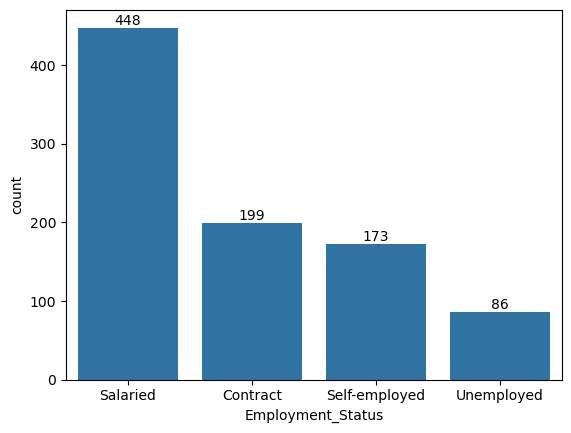

In [4]:
emp_st_count = df['Employment_Status'].value_counts()
ax = sns.barplot(emp_st_count)
ax.bar_label(ax.containers[0])

[Text(0, 0, '192'),
 Text(0, 0, '192'),
 Text(0, 0, '180'),
 Text(0, 0, '169'),
 Text(0, 0, '169')]

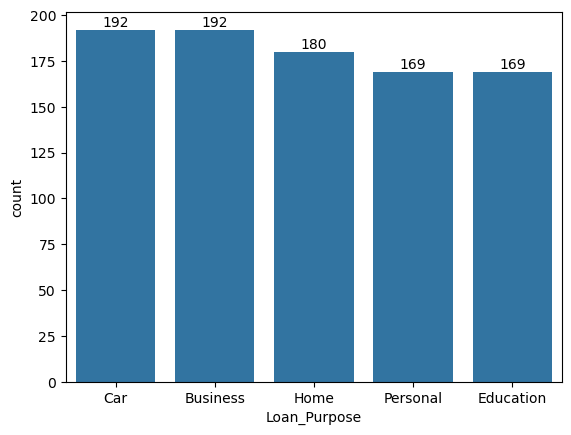

In [5]:
loan_prp_count = df['Loan_Purpose'].value_counts()
ax = sns.barplot(loan_prp_count)
ax.bar_label(ax.containers[0])

[Text(0, 0, '538'), Text(0, 0, '365')]

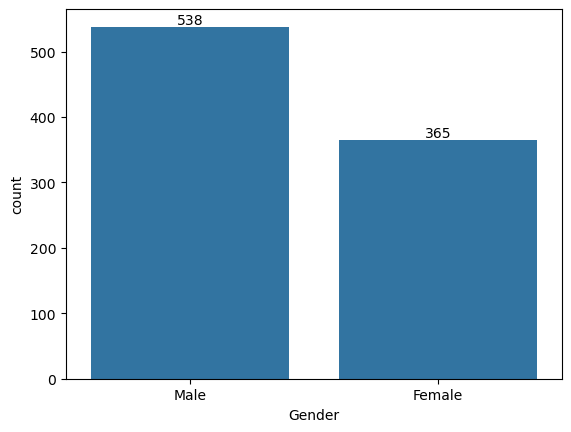

In [6]:
gender_cnt = df['Gender'].value_counts()
ax = sns.barplot(gender_cnt)
ax.bar_label(ax.containers[0])

[Text(0, 0, '351'),
 Text(0, 0, '191'),
 Text(0, 0, '136'),
 Text(0, 0, '130'),
 Text(0, 0, '95')]

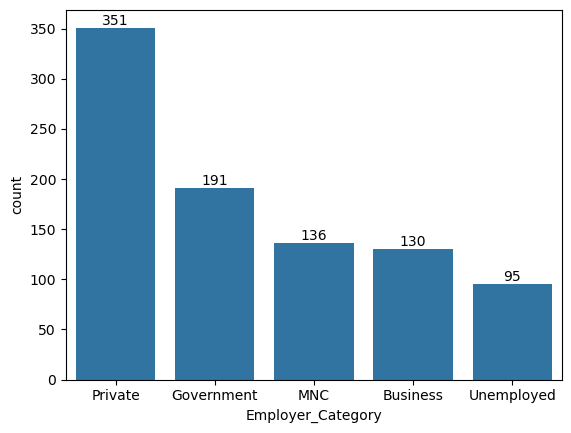

In [7]:
emp_cat_cnt = df['Employer_Category'].value_counts()
ax = sns.barplot(emp_cat_cnt)
ax.bar_label(ax.containers[0])

<Axes: xlabel='Applicant_Income', ylabel='Count'>

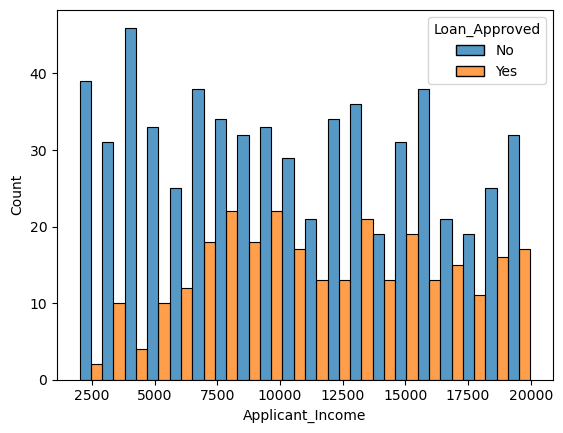

In [8]:
# analyze income

sns.histplot(
    data = df,
    x = 'Applicant_Income',
    bins = 20,
    hue = 'Loan_Approved',
    multiple = "dodge"
)

<Axes: xlabel='Credit_Score', ylabel='Count'>

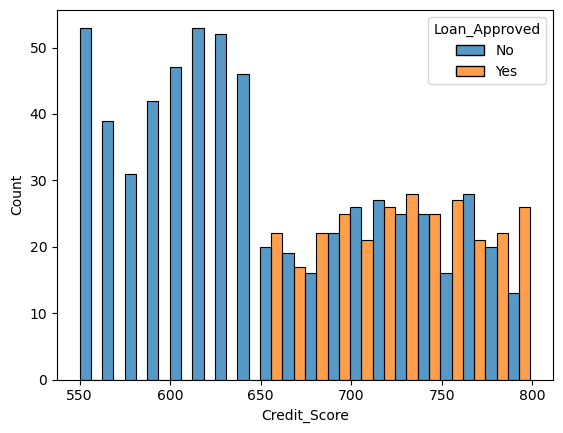

In [9]:
sns.histplot(
    data = df,
    x = 'Credit_Score',
    bins = 20,
    hue = 'Loan_Approved',
    multiple = 'dodge'
)

<Axes: xlabel='Coapplicant_Income', ylabel='Count'>

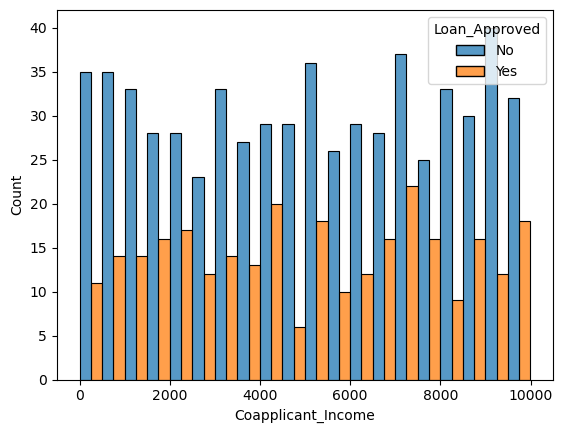

In [10]:
sns.histplot(
    data = df,
    x = 'Coapplicant_Income',
    bins = 20,
    hue = 'Loan_Approved',
    multiple = 'dodge'
)

<Axes: xlabel='Loan_Approved', ylabel='Applicant_Income'>

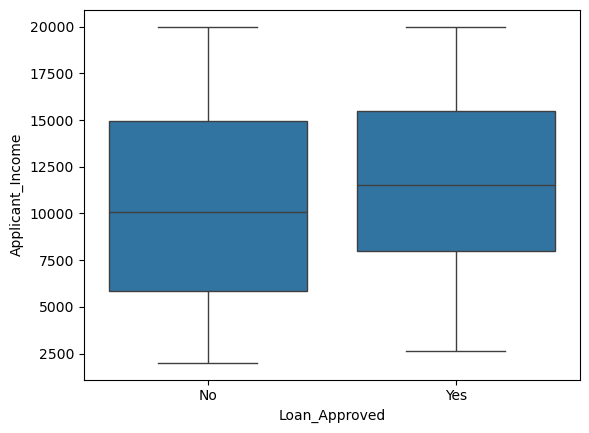

In [11]:
# outliers boxplot

sns.boxplot(
    data= df,
    x = 'Loan_Approved',
    y = 'Applicant_Income'
)

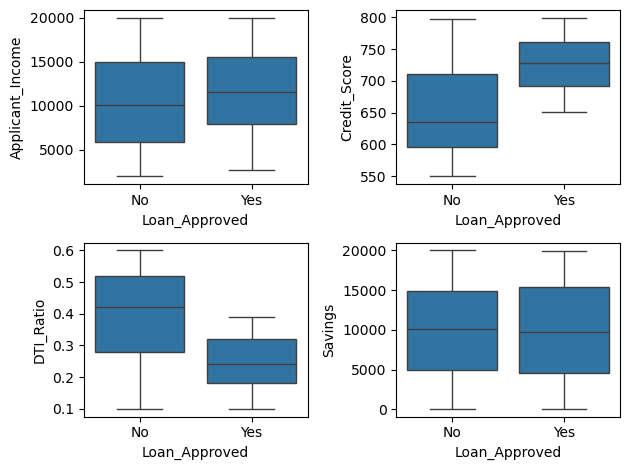

In [12]:
fig , ax = plt.subplots(2,2)

sns.boxplot(ax = ax[0,0], data = df, x = 'Loan_Approved', y = 'Applicant_Income')
sns.boxplot(ax = ax[0,1], data = df, x = 'Loan_Approved', y = 'Credit_Score')
sns.boxplot(ax = ax[1,0], data = df, x = 'Loan_Approved', y = 'DTI_Ratio')
sns.boxplot(ax = ax[1,1], data = df, x = 'Loan_Approved', y = 'Savings')

plt.tight_layout()

<Axes: >

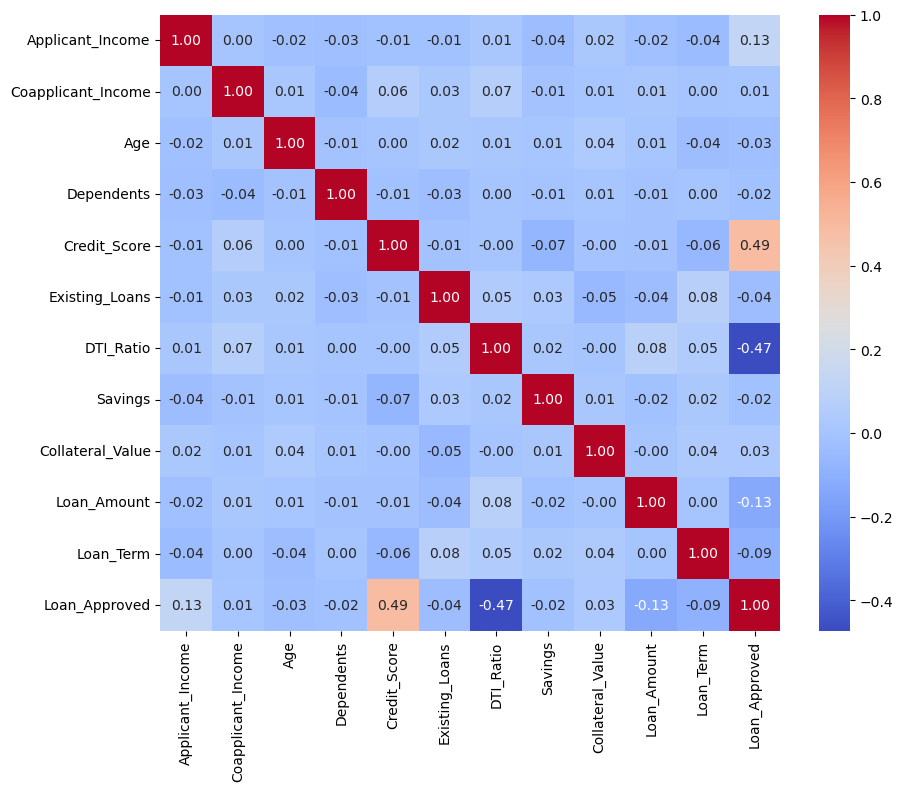

In [13]:
# heat map

temp = df.copy()
temp['Loan_Approved'] = temp['Loan_Approved'].map({'No': 0, 'Yes': 1})

corr = temp.select_dtypes(include='number').corr()

plt.figure(figsize=(10,8))
sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm'
)

In [14]:
df.columns

Index(['Applicant_Income', 'Coapplicant_Income', 'Employment_Status', 'Age',
       'Marital_Status', 'Dependents', 'Credit_Score', 'Existing_Loans',
       'DTI_Ratio', 'Savings', 'Collateral_Value', 'Loan_Amount', 'Loan_Term',
       'Loan_Purpose', 'Property_Area', 'Education_Level', 'Gender',
       'Employer_Category', 'Loan_Approved'],
      dtype='object')

## Feature Engneering

In [15]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

df['Credit_Score_sq'] = df['Credit_Score']**2
df['DTI_Ratio_sq'] = df['DTI_Ratio']**2

df['Applicant_Income'] = np.log1p(df['Applicant_Income'])

X = df.drop(columns = ['Loan_Approved', 'Credit_Score', 'DTI_Ratio'])
y = LabelEncoder().fit_transform(df['Loan_Approved'])  # no - 0, yes- 1

X_train , X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state = 42
)

In [16]:
num_cols = X_train.select_dtypes(include=['float64']).columns
cat_cols = X_train.select_dtypes(include=['object']).columns

num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='mean')),
     ('scaler', StandardScaler())
])


cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='first', handle_unknown='ignore'))
])


preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
])

## Models

In [17]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import AdaBoostClassifier

models = {
    'LogisticRegression' : LogisticRegression(),
    'KNN' : KNeighborsClassifier(),
    'nb' : GaussianNB(),
    'dt' : DecisionTreeClassifier(max_depth=5, min_samples_leaf=20,random_state=42),
    'rf' : RandomForestClassifier(n_estimators=200, oob_score=True, max_depth=5, random_state=42),
    'gb' : GradientBoostingClassifier(learning_rate=0.1,n_estimators=200, max_depth=5, random_state=42),
    'adc' : AdaBoostClassifier(n_estimators=100, random_state=42),
}

In [18]:
from sklearn.model_selection import cross_val_score

for name, m in models.items():
    pipe = Pipeline([('prep', preprocessor), ('model', m)])
    scores = cross_val_score(pipe, X_train, y_train, cv=5, scoring='f1')
    print(name, scores.mean())

LogisticRegression 0.7732916637774485
KNN 0.7369124547977461
nb 0.7657821154866797
dt 0.9168377160296675
rf 0.8922442521080068
gb 0.9302732562836494
adc 0.9123409730024733


## Final Model

In [19]:
from sklearn.metrics import classification_report , confusion_matrix

final_pipeline = Pipeline([
    ('prep', preprocessor),
    ('model', GradientBoostingClassifier(learning_rate=0.1, n_estimators=1000, max_depth=5, random_state=42))
])

final_pipeline.fit(X_train, y_train)
y_pred = final_pipeline.predict(X_test)

print(classification_report(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.98      0.95      0.96       129
           1       0.89      0.97      0.93        61

    accuracy                           0.95       190
   macro avg       0.94      0.96      0.95       190
weighted avg       0.95      0.95      0.95       190

[[122   7]
 [  2  59]]
